In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit


In [13]:
data = sm.datasets.sunspots.load_pandas().data
sunspots = data["SUNACTIVITY"].values

# Create lagged features
def add_lagged_features(data, lag=12):
    X, y = [], []

    for i in range(lag, len(data)):
        X.append(data[i-lag:i])
        y.append(data[i])

    return np.array(X), np.array(y)

X, y = add_lagged_features(sunspots, lag=12)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    shuffle=False
)

# Scale inputs
x_scaler = StandardScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Scale targets
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

In [14]:
results = []
predictions = {}

for n_layers in range(1, 6):

    # 50 neurons for each hidden layer
    hidden_layers = (50,) * n_layers

    mlp = MLPRegressor(
        hidden_layer_sizes=hidden_layers,
        activation="relu",
        solver="adam",
        max_iter=2500,
        random_state=42
    )

    # Train
    mlp.fit(X_train_scaled, y_train_scaled)

    # Predict
    y_pred_scaled = mlp.predict(X_test_scaled)

    # Convert predictions to original scale
    y_pred = y_scaler.inverse_transform(
        y_pred_scaled.reshape(-1, 1)
    ).ravel()

    # Evaluate
    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    results.append({
        "Hidden Layers": n_layers,
        "RMSE": rmse,
        "MAE": mae
    })

    predictions[n_layers] = y_pred

results_df = pd.DataFrame(results)

print(results_df)

   Hidden Layers       RMSE        MAE
0              1  17.704217  13.776954
1              2  20.886130  16.122600
2              3  19.536947  15.877979
3              4  21.305167  16.548322
4              5  20.461445  16.635903


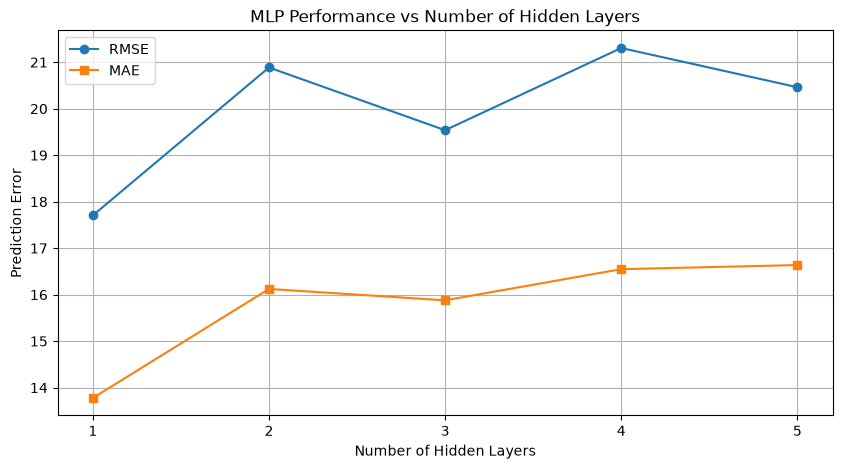

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    results_df["Hidden Layers"],
    results_df["RMSE"],
    marker="o",
    label="RMSE"
)

plt.plot(
    results_df["Hidden Layers"],
    results_df["MAE"],
    marker="s",
    label="MAE"
)

plt.xlabel("Number of Hidden Layers")
plt.ylabel("Prediction Error")
plt.title("MLP Performance vs Number of Hidden Layers")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.show()